Predikce hodinové spotřeby elektřiny jedné domácnosti na základě času, předchozí spotřeby a venkovní teploty s využitím datasetu "Individual Household Electric Power Consumption in Sceaux, Paris"

# Setup

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

SEED = 20261017

def stream_seed(stream_id, repetition=0):
    return int(np.random.SeedSequence([SEED, stream_id, repetition]).generate_state(1)[0])

DATA = Path("data")
assert (DATA / "sceaux_hourly_temperature.csv").is_file(), "Temperature file not loaded"

TARGET = "Global_active_power"

# Datasets

**Household consumption** ,easurements of electric power consumption in one household with a one-minute sampling rate in Sceaux (7km of Paris, France) between December 2006 and November 2010 (47 months).
Requires `pip install ucimlrepo`

Source: https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption

In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
dataset = fetch_ucirepo(id=235) 
  
# data (as pandas dataframes) 
df_consumption = dataset.data.original.replace(["", "?"], pd.NA)
print(df_consumption.head())


/Users/angelina/UHK/Masters Study/UHK2_Sem3/SU/ukol1/.venv/lib/python3.14/site-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (2: Global_active_power, 3: Global_reactive_power, 4: Voltage, 5: Global_intensity, 6: Sub_metering_1, 7: Sub_metering_2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


         Date      Time Global_active_power Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00               4.216                 0.418  234.840   
1  16/12/2006  17:25:00               5.360                 0.436  233.630   
2  16/12/2006  17:26:00               5.374                 0.498  233.290   
3  16/12/2006  17:27:00               5.388                 0.502  233.740   
4  16/12/2006  17:28:00               3.666                 0.528  235.680   

  Global_intensity Sub_metering_1 Sub_metering_2  Sub_metering_3  
0           18.400          0.000          1.000            17.0  
1           23.000          0.000          1.000            16.0  
2           23.000          0.000          2.000            17.0  
3           23.000          0.000          1.000            17.0  
4           15.800          0.000          1.000            17.0  


**Temperature dataset** downloaded from Open Meteo with per-hour historic temperature from the area of Sceaux.
- latitude 48.7764, longitude 2.2903
- weather model ERA5-Land
- from 01.12.2006 until 30.11.2010
- timezone UTC

Data source: https://open-meteo.com/en/docs/historical-weather-api?utm_source=chatgpt.com&bounding_box=-90,-180,90,180

In [4]:
df_temperature_metadata = pd.read_csv(DATA / "sceaux_temperature_metadata.csv")
print(df_temperature_metadata.head())

df_temperature = pd.read_csv(DATA / "sceaux_hourly_temperature.csv")
print(df_temperature.head())

    latitude  longitude  elevation  utc_offset_seconds timezone  \
0  48.800003   2.300003       94.0                   0      GMT   

  timezone_abbreviation  
0                   GMT  
               time  temperature_2m (°C)
0  2006-12-01T00:00                  6.5
1  2006-12-01T01:00                  6.1
2  2006-12-01T02:00                  5.9
3  2006-12-01T03:00                  5.7
4  2006-12-01T04:00                  5.4


# Data preparation

In [5]:
# helpers
def audit(frame, unique_features):
    display(frame.head())
    print("Size:", frame.shape)
    display(pd.DataFrame({"type": frame.dtypes, "missing": frame.isna().sum()}))
    print("Exact duplicates:", frame.duplicated().sum())
    
    for feature in unique_features:
        assert frame[feature].is_unique, print("Duplicated:", frame[feature].duplicated().sum())
    print("Verified unique features:", unique_features)

def audit_complete_frame(frame, features, target):    
    assert frame[features + [target]].notna().all().all()
    assert np.isfinite(frame[features + [target]].to_numpy(dtype=float)).all()

def scores(y, prediction):
    return {"MAE [kWh]": mean_absolute_error(y, prediction),
            "RMSE [kWh]": root_mean_squared_error(y, prediction)}

## Basic audit of datasets

In [6]:
audit(df_temperature, ["time"])

,time,temperature_2m (°C)
0,2006-12-01T00:00,6.5
1,2006-12-01T01:00,6.1
2,2006-12-01T02:00,5.9
3,2006-12-01T03:00,5.7
4,2006-12-01T04:00,5.4


Size: (35064, 2)


,type,missing
time,str,0
temperature_2m (°C),float64,0


Exact duplicates: 0
Verified unique features: ['time']


In [7]:
audit(df_consumption, [])

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


Size: (2075259, 9)


,type,missing
Date,str,0
Time,str,0
Global_active_power,object,25979
Global_reactive_power,object,25979
Voltage,object,25979
Global_intensity,object,25979
Sub_metering_1,object,25979
Sub_metering_2,object,25979
Sub_metering_3,float64,25979


Exact duplicates: 0
Verified unique features: []


Output:
* **Temperature dataset** 
    * contains no duplicates and missing values
    * types do not require the transformation: time is string and temperature is float
    * time is verified to be unique across the whole dataset
    * UTC timezone (from metadata)
* **Consumption dataset** 
    * contains no duplicates
    * point of interest is 'Global_active_power', other features may be dropped
    * 'Global_active_power' has 25979 missing values
    * 'Global_active_power' and other measurements are of type object, requires the transformation to float
    * the measurements are per minute, while the temperature data is per hour
    * transformation to the kWh will be applied on 'Global_active_power', along with that the missing values will be handled.
    * 'Date' and 'Time' columns will be merged to easily map to 'time' form temperature dataset after the transformation to per-hour measurements
    * NOTE: the timezone is not clear from the datasource, therefore UTC is assumed

## Data pre-processing

### Household consumption dataset
1. limit only to 'Date', 'Time' and 'Global_active_power'
2. transform the 'Global_active_power' from object to float64
3. merge 'Date' and 'Time' columns into one in format similar to 'time' from temeprature data "yyyy-mm-ddThh:mm" as a start hour of a one-hour timestamp
4. transform the per-minute time series to per-hour 
    - SUM(Global_active_power in 60 minutes per hour) / 60
    - before that, check how many missing values in scope of one hour
        - count valid measurements for each hour
        - keep hours with 60 valid minute measurements
        - mark hours with missing values with NA for a start

In [8]:
# 1. Limit only to 'Date', 'Time' and 'Global_active_power'.
# Consumption dataset contains additional fields, 
# but the point of interest is `Global_active_power`, so other columns will be dropped.
df_consumption_target = df_consumption[["Date", "Time", "Global_active_power"]]
print(df_consumption_target.head())

         Date      Time Global_active_power
0  16/12/2006  17:24:00               4.216
1  16/12/2006  17:25:00               5.360
2  16/12/2006  17:26:00               5.374
3  16/12/2006  17:27:00               5.388
4  16/12/2006  17:28:00               3.666


In [9]:
# 2. transform the 'Global_active_power' from object to float64
numeric_cols = ["Global_active_power"]

df_consumption_target[numeric_cols] = (
    df_consumption_target[numeric_cols]
    .apply(pd.to_numeric, errors="coerce")
    .astype("float64")
)

print(df_consumption_target.dtypes)

Date                       str
Time                       str
Global_active_power    float64
dtype: object


In [10]:
# 3. Merge Date and Time into the start of each one-hour interval.
df_consumption_target_time = df_consumption_target.copy()
df_consumption_target_time["time"] = (
    pd.to_datetime(
        df_consumption_target["Date"] + " " + df_consumption_target["Time"],
        format="%d/%m/%Y %H:%M:%S",
    )
    .dt.floor("h")
)
df_consumption_target_time = df_consumption_target_time.drop(columns=["Date", "Time"])

print(df_consumption_target_time.head())
print(df_consumption_target_time.dtypes)

   Global_active_power                time
0                4.216 2006-12-16 17:00:00
1                5.360 2006-12-16 17:00:00
2                5.374 2006-12-16 17:00:00
3                5.388 2006-12-16 17:00:00
4                3.666 2006-12-16 17:00:00
Global_active_power           float64
time                   datetime64[us]
dtype: object


In [11]:
# Transform
df_consumption_transformed = None

# Count valid and missing measurements for each hour before transformation.
# size counts all rows, count takes only non-missing
hourly_measurement_counts = (
    df_consumption_target_time.groupby("time")["Global_active_power"]
    .agg(total_values="size", valid_values="count")
)
hourly_measurement_counts["missing_values"] = (
    hourly_measurement_counts["total_values"]
    - hourly_measurement_counts["valid_values"]
)

# Display hours containing at least one missing measurement.
display(
    hourly_measurement_counts.loc[
        hourly_measurement_counts["missing_values"] > 0,
        ["valid_values", "missing_values"],
    ].reset_index()
)

,time,valid_values,missing_values
0,2006-12-21 11:00:00,58,2
1,2006-12-30 10:00:00,58,2
2,2007-01-14 18:00:00,59,1
3,2007-01-28 17:00:00,59,1
4,2007-02-22 22:00:00,58,2
...,...,...,...
497,2010-09-28 16:00:00,0,60
498,2010-09-28 17:00:00,0,60
499,2010-09-28 18:00:00,0,60
500,2010-09-28 19:00:00,47,13


Missing values: some hours miss only 1-2 values, some have no valid value. 

- Target consumption missing: exclude in all cases
- Consumption 24 hours earlier is missing: excluded if previous consumption is a feature

Aggregate to hourly consumption. 
- Calculate sum / 60 only for hours with 60 valid minute measurements. 
- Otherwise, set hourly consumption to NaN. Preserve a regular hourly timeline, including those NaN hours.


In [12]:
# 1. Aggregate complete hours to energy consumption in kWh.
minute_consumption = df_consumption_target_time.assign(
    time=pd.to_datetime(df_consumption_target_time["time"], format="%Y-%m-%dT%H:%M")
).set_index("time")["Global_active_power"]

# Resampling also inserts absent hours, preserving the hourly timeline.
hourly_consumption = minute_consumption.resample("h")
valid_measurements = hourly_consumption.count()
df_consumption_transformed = (
    (hourly_consumption.sum(min_count=60) / 60)
    .where(valid_measurements.eq(60))
    .rename("Global_active_power")
    .reset_index()
)
df_consumption_transformed["time"] = (
    df_consumption_transformed["time"].dt.strftime("%Y-%m-%dT%H:%M")
)
df_consumption_hourly = df_consumption_transformed.copy()

# Incomplete and absent hours must have missing consumption.
assert df_consumption_hourly["Global_active_power"].isna().to_numpy()[
    valid_measurements.ne(60).to_numpy()
].all()
display(df_consumption_hourly.head())


,time,Global_active_power
0,2006-12-16T17:00,NaN
1,2006-12-16T18:00,3.632200
2,2006-12-16T19:00,3.400233
3,2006-12-16T20:00,3.268567
4,2006-12-16T21:00,3.056467


Create yesterday’s consumption feature: consumption exactly 24 hours earlier.

In [13]:
df_consumption_master = df_consumption_hourly.copy()

# dataframe has one row for every consecutive hour
# if target consumption is NaN, lag is also NaN
df_consumption_master["consumption_lag_24h"] = (
    df_consumption_master["Global_active_power"].shift(24)
)

print(df_consumption_master.head())

               time  Global_active_power  consumption_lag_24h
0  2006-12-16T17:00                  NaN                  NaN
1  2006-12-16T18:00             3.632200                  NaN
2  2006-12-16T19:00             3.400233                  NaN
3  2006-12-16T20:00             3.268567                  NaN
4  2006-12-16T21:00             3.056467                  NaN


## Merge datasets

### Data range check

In [14]:
# Date range comparison
print("Temperature time range:", df_temperature.time.min(), "-", df_temperature.time.max())
print("Consumption time range:", df_consumption_master.time.min(), "-", df_consumption_master.time.max())

Temperature time range: 2006-12-01T00:00 - 2010-11-30T23:00
Consumption time range: 2006-12-16T17:00 - 2010-11-26T21:00


Temparature: 1.12.2026 - 30.11.2010

Consumption: 16.12.2006 - 26.11.2010

### Merge

In [15]:
# Keep every consumption hour and match its temperature by time.

df_master = df_consumption_master.assign(
    time=pd.to_datetime(df_consumption_master["time"])
).merge(
    df_temperature.rename(columns={"temperature_2m (°C)": "temperature"}).assign(
        time=pd.to_datetime(df_temperature["time"])
    )[["time", "temperature"]],
    on="time",
    how="left",
    validate="one_to_one",
)

audit(df_master, ["time"])

,time,Global_active_power,consumption_lag_24h,temperature
0,2006-12-16 17:00:00,NaN,NaN,6.4
1,2006-12-16 18:00:00,3.632200,NaN,6.2
2,2006-12-16 19:00:00,3.400233,NaN,5.9
3,2006-12-16 20:00:00,3.268567,NaN,5.1
4,2006-12-16 21:00:00,3.056467,NaN,4.3


Size: (34589, 4)


,type,missing
time,datetime64[us],0
Global_active_power,float64,504
consumption_lag_24h,float64,527
temperature,float64,0


Exact duplicates: 0
Verified unique features: ['time']


### Add hour and day_of_week

In [16]:
# add separate columns hours and day of week
df_master["hour"] = df_master["time"].dt.hour
df_master["day_of_week"] = df_master["time"].dt.dayofweek # Monday = 0, Sunday = 6

In [17]:
temperature = "temperature"
lag = "consumption_lag_24h"
hour = "hour"
day_of_week = "day_of_week"

# option A - temperature, hour, day_of_week
df_A = df_master.dropna(subset=[TARGET, temperature, hour, day_of_week]).copy()

# option B -  A + lag data
df_B = df_master.dropna(subset=[TARGET, temperature, hour, day_of_week, lag]).copy()

# Model A: calendar and temperature

## Train, Val, Test split

The dataset will be split chronologically, with earliest 70% used as train, next 15% as validation, and last 15% as test.

In [18]:
# helper for chronological split
timeline = df_master.sort_index().index
train_end = timeline[int(len(timeline) * 0.70)]
val_end = timeline[int(len(timeline) * 0.85)]

def split_by_time(df):
    df = df.sort_index()

    train = df.loc[df.index < train_end].copy()
    val = df.loc[
        (df.index >= train_end) & (df.index < val_end)
    ].copy()
    test = df.loc[df.index >= val_end].copy()

    return train, val, test

### For model A, without the lagged feture, random split is enough

In [19]:
train_A, val_A, test_A = split_by_time(df_A)

print("Train:", len(train_A), "Validation:", len(val_A), "Test:", len(test_A))

# disjoint checks
sets = [set(part.time) for part in [train_A, val_A, test_A]]
assert all(sets[i].isdisjoint(sets[j]) for i in range(3) for j in range(i+1, 3))
assert len(set.union(*sets)) == len(df_A)

Train: 24022 Validation: 5090 Test: 4973


## Statistics on Train

For model A

,temperature,hour,day_of_week,Global_active_power
count,24022.000000,24022.000000,24022.000000,24022.000000
mean,11.377175,11.495421,2.993131,1.085161
std,6.854908,6.925754,1.996999,0.927820
min,-10.400000,0.000000,0.000000,0.124000
25%,6.400000,5.000000,1.000000,0.322867
50%,11.400000,11.000000,3.000000,0.763067
75%,16.400000,17.000000,5.000000,1.575650
max,34.800000,23.000000,6.000000,6.560533


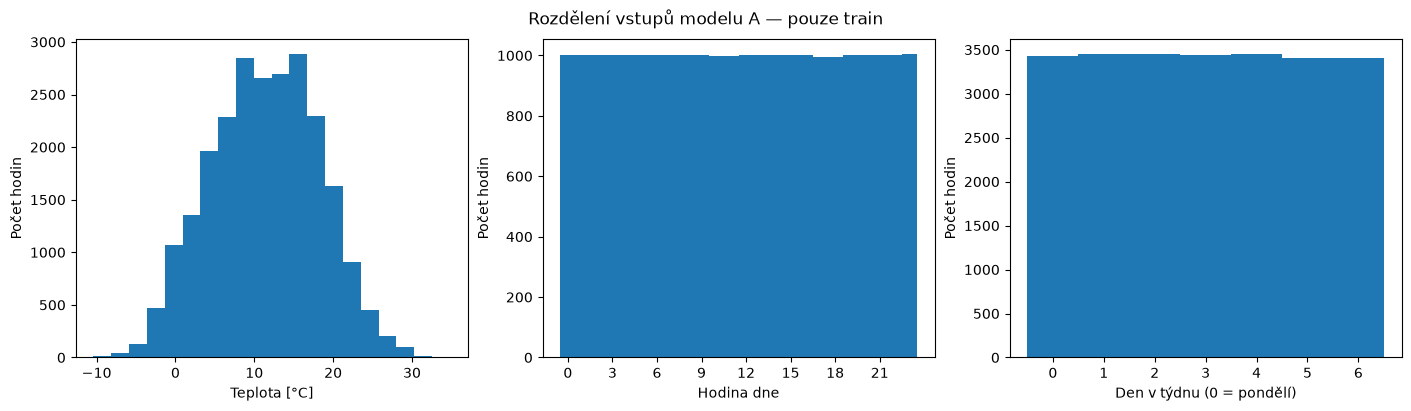

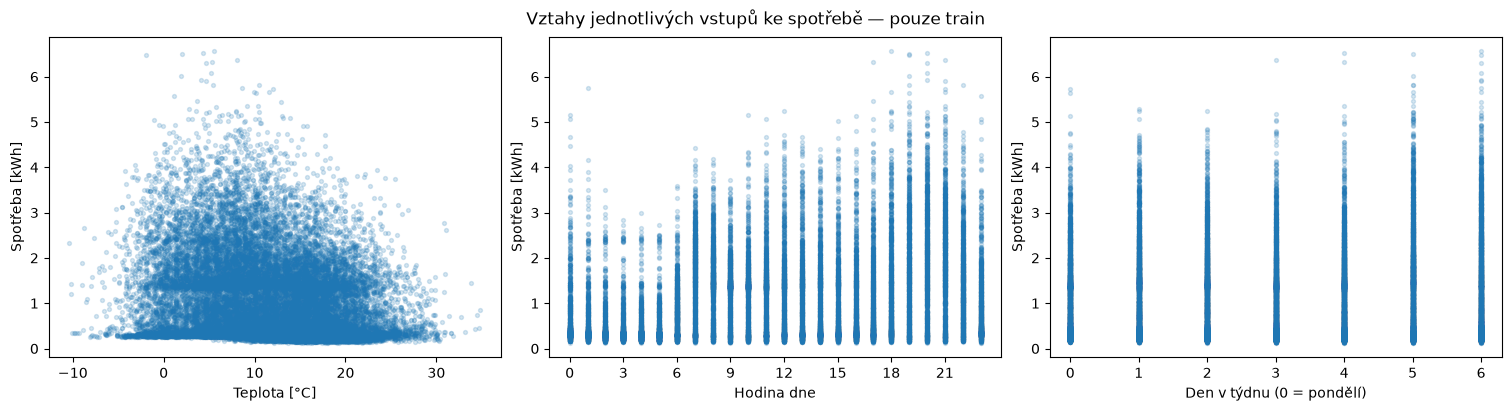

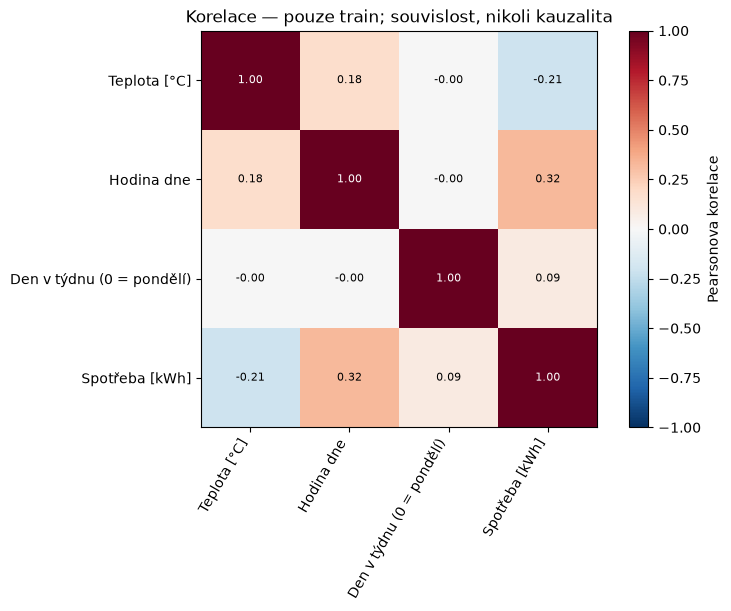

In [20]:
# EDA of A model only on train data
FEATURES_A = [temperature, hour, day_of_week]
labels = ["Teplota [°C]", "Hodina dne", "Den v týdnu (0 = pondělí)"]
target_label = "Spotřeba [kWh]"

display(train_A[FEATURES_A + [TARGET]].describe())

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, column, label in zip(axes.flat, FEATURES_A, labels):
    # interval borders of calendar features are between whole numbers
    bins = (np.arange(25) - 0.5 if column == hour else
            np.arange(8) - 0.5 if column == day_of_week else 20)
    ax.hist(train_A[column], bins=bins)
    ax.set(xlabel=label, ylabel="Počet hodin")
    if column == hour:
        ax.set_xticks(range(0, 24, 3))
    elif column == day_of_week:
        ax.set_xticks(range(7))
fig.suptitle("Rozdělení vstupů modelu A — pouze train")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, column, label in zip(axes.flat, FEATURES_A, labels):
    ax.scatter(train_A[column], train_A[TARGET], alpha=.18, s=8)
    ax.set(xlabel=label, ylabel=target_label)
    if column == hour:
        ax.set_xticks(range(0, 24, 3))
    elif column == day_of_week:
        ax.set_xticks(range(7))
fig.suptitle("Vztahy jednotlivých vstupů ke spotřebě — pouze train")
plt.show()

# Pearsonova korelace zachycuje lineární vztahy. U cyklických kalendářních
# vstupů nemusí vystihovat vztah ke spotřebě; nejde o důkaz kauzality.
correlation = train_A[FEATURES_A + [TARGET]].corr()
correlation_labels = labels + [target_label]
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
chart = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(correlation)), correlation_labels, rotation=60, ha="right")
ax.set_yticks(range(len(correlation)), correlation_labels)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        value = correlation.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > .5 else "black")
fig.colorbar(chart, ax=ax, label="Pearsonova korelace")
ax.set_title("Korelace — pouze train; souvislost, nikoli kauzalita")
plt.show()


Note: day of week has very low correlation with consumption. TODO if needed to keep, or remove fully

### Scaler

In [21]:
# Fit the scaler on training features only to avoid data leakage.
scaler_A = StandardScaler()
scaler_A.fit(train_A[FEATURES_A])

# Save the fitted parameters for later checks that the scaler stays unchanged.
scaler_A_snapshot = (
    scaler_A.mean_.copy(),
    scaler_A.scale_.copy(),
    int(scaler_A.n_samples_seen_),
)

z_train_A = pd.DataFrame(
    scaler_A.transform(train_A[FEATURES_A]),
    columns=FEATURES_A,
    index=train_A.index,
)
z_val_A = pd.DataFrame(
    scaler_A.transform(val_A[FEATURES_A]),
    columns=FEATURES_A,
    index=val_A.index,
)

# Transform test features only in the final test evaluation cell.
display(train_A[FEATURES_A].head())
display(z_train_A.head())
display(z_train_A.agg(["mean", lambda col: col.std(ddof=0)]))

y_train_A = train_A[TARGET]
y_val_A = val_A[TARGET]


,temperature,hour,day_of_week
1,6.2,18,5
2,5.9,19,5
3,5.1,20,5
4,4.3,21,5
5,3.4,22,5


,temperature,hour,day_of_week
1,-0.755267,0.939207,1.004963
2,-0.799032,1.083598,1.004963
3,-0.915739,1.227990,1.004963
4,-1.032446,1.372382,1.004963
5,-1.163742,1.516773,1.004963


,temperature,hour,day_of_week
mean,-1.135827e-16,1.282982e-16,3.105778e-17
<lambda>,1.000000e+00,1.000000e+00,1.000000e+00


In [22]:
# Fit Model A and a mean baseline on training data only.
model_A = LinearRegression()
model_A.fit(z_train_A, y_train_A)

dummy_A = DummyRegressor(strategy="mean")
dummy_A.fit(z_train_A, y_train_A)

# Compare training and validation errors in kWh.
pred_train_A = model_A.predict(z_train_A)
pred_val_A = model_A.predict(z_val_A)
pred_train_dummy_A = dummy_A.predict(z_train_A)
pred_val_dummy_A = dummy_A.predict(z_val_A)

results_A = pd.DataFrame([
    {"Model": "Model A (linear regression)", "Split": "Train",
     **scores(y_train_A, pred_train_A)},
    {"Model": "Model A (linear regression)", "Split": "Validation",
     **scores(y_val_A, pred_val_A)},
    {"Model": "Dummy (training mean)", "Split": "Train",
     **scores(y_train_A, pred_train_dummy_A)},
    {"Model": "Dummy (training mean)", "Split": "Validation",
     **scores(y_val_A, pred_val_dummy_A)},
]).set_index(["Model", "Split"])
display(results_A)


MAE [kWh]  RMSE [kWh]
Model                       Split                            
Model A (linear regression) Train        0.652331    0.837523
                            Validation   0.656638    0.820850
Dummy (training mean)       Train        0.747795    0.927801
                            Validation   0.726818    0.900330

# Model B: calendar, temperature, and lagged consumption

Model B adds consumption exactly 24 hours earlier to Model A's features. Use the same chronological split boundaries as Model A. Rows with missing lagged consumption have already been excluded from `df_B`.


## Train, validation, and test split

In [23]:
FEATURES_B = [temperature, hour, day_of_week, lag]
train_B, val_B, test_B = split_by_time(df_B)

print("Train:", len(train_B), "Validation:", len(val_B), "Test:", len(test_B))

# Check complete inputs, disjoint timestamps, and chronological ordering.
for part in [train_B, val_B, test_B]:
    audit_complete_frame(part, FEATURES_B, TARGET)
sets_B = [set(part.time) for part in [train_B, val_B, test_B]]
assert all(sets_B[i].isdisjoint(sets_B[j]) for i in range(3) for j in range(i + 1, 3))
assert len(set.union(*sets_B)) == len(df_B)
assert train_B.time.max() < val_B.time.min()
assert val_B.time.max() < test_B.time.min()


Train: 23880 Validation: 5033 Test: 4920


## Statistics on training data

,temperature,hour,day_of_week,consumption_lag_24h,Global_active_power
count,23880.000000,23880.000000,23880.000000,23880.000000,23880.000000
mean,11.366420,11.486013,2.995561,1.084411,1.084362
std,6.849923,6.928806,1.994292,0.927457,0.927399
min,-10.400000,0.000000,0.000000,0.124000,0.124000
25%,6.400000,5.000000,1.000000,0.322417,0.322792
50%,11.400000,11.000000,3.000000,0.762867,0.763050
75%,16.400000,17.000000,5.000000,1.575300,1.574342
max,34.800000,23.000000,6.000000,6.560533,6.560533


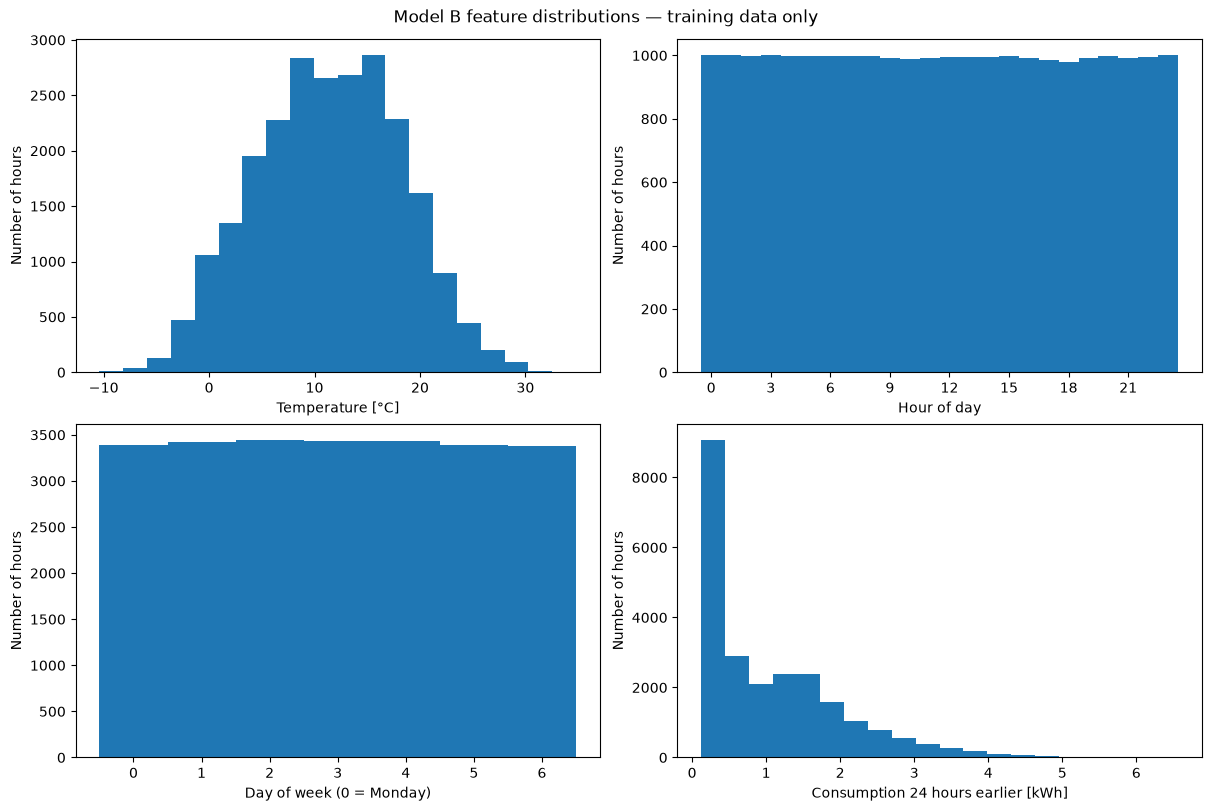

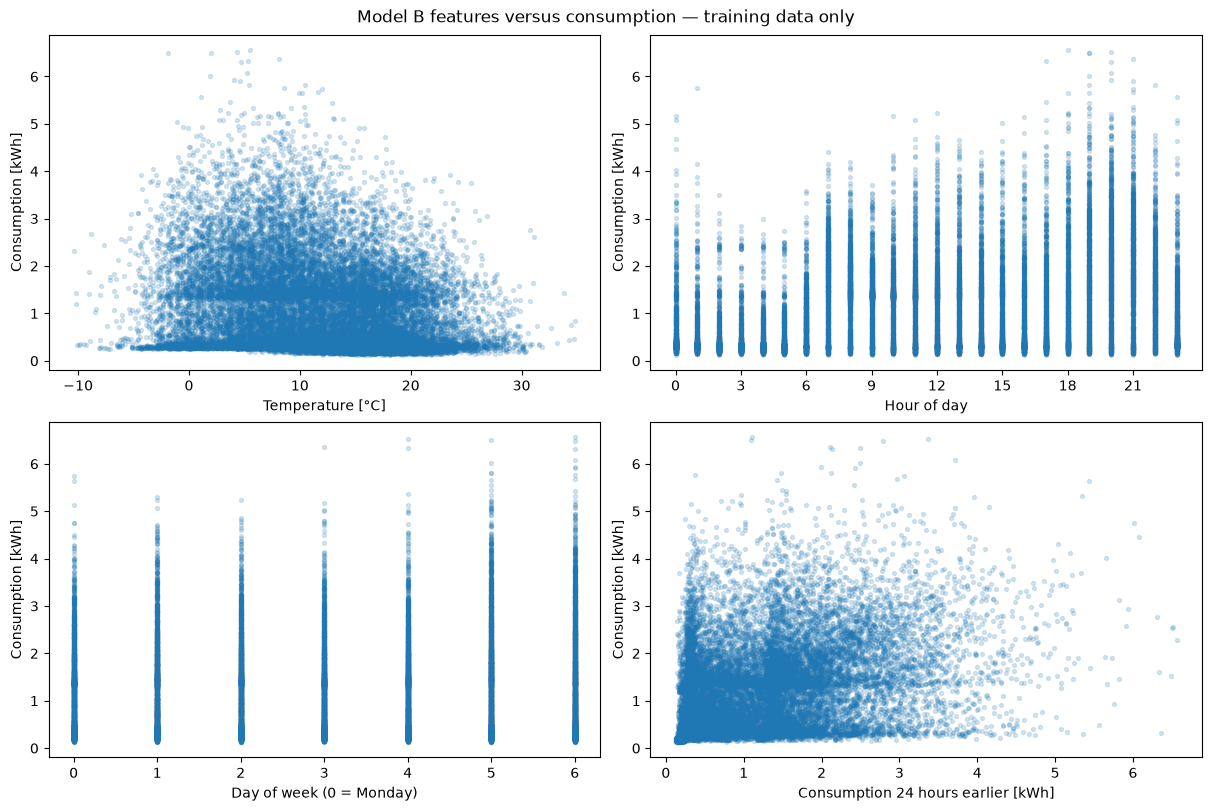

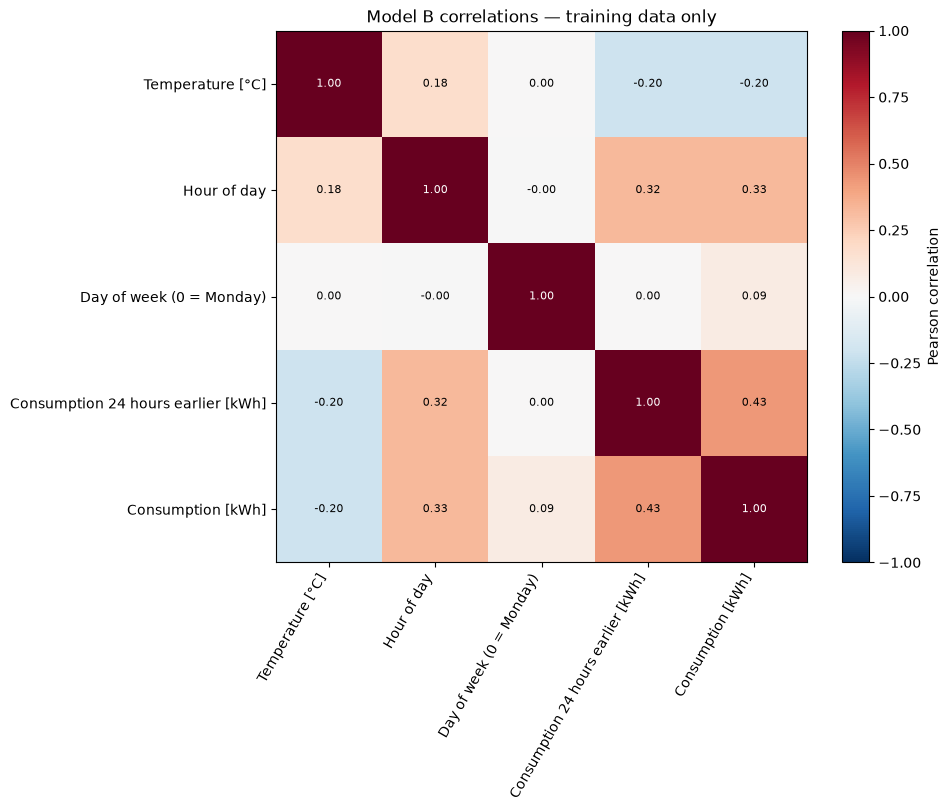

In [24]:
# Explore Model B features using training data only.
labels_B = ["Temperature [°C]", "Hour of day", "Day of week (0 = Monday)",
            "Consumption 24 hours earlier [kWh]"]
target_label_B = "Consumption [kWh]"
display(train_B[FEATURES_B + [TARGET]].describe())

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, column, label in zip(axes.flat, FEATURES_B, labels_B):
    # Center calendar bins on their integer values.
    bins = (np.arange(25) - 0.5 if column == hour else
            np.arange(8) - 0.5 if column == day_of_week else 20)
    ax.hist(train_B[column], bins=bins)
    ax.set(xlabel=label, ylabel="Number of hours")
    if column == hour:
        ax.set_xticks(range(0, 24, 3))
    elif column == day_of_week:
        ax.set_xticks(range(7))
fig.suptitle("Model B feature distributions — training data only")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, column, label in zip(axes.flat, FEATURES_B, labels_B):
    ax.scatter(train_B[column], train_B[TARGET], alpha=.18, s=8)
    ax.set(xlabel=label, ylabel=target_label_B)
    if column == hour:
        ax.set_xticks(range(0, 24, 3))
    elif column == day_of_week:
        ax.set_xticks(range(7))
fig.suptitle("Model B features versus consumption — training data only")
plt.show()

# Pearson correlation measures linear association, not causation.
# Numeric calendar values may hide cyclic relationships.
correlation_B = train_B[FEATURES_B + [TARGET]].corr()
correlation_labels_B = labels_B + [target_label_B]
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
chart = ax.imshow(correlation_B, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(correlation_B)), correlation_labels_B, rotation=60, ha="right")
ax.set_yticks(range(len(correlation_B)), correlation_labels_B)
for i in range(len(correlation_B)):
    for j in range(len(correlation_B)):
        value = correlation_B.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > .5 else "black")
fig.colorbar(chart, ax=ax, label="Pearson correlation")
ax.set_title("Model B correlations — training data only")
plt.show()


## Scaling

In [25]:
# Fit the scaler on training features only to avoid data leakage.
scaler_B = StandardScaler()
scaler_B.fit(train_B[FEATURES_B])

# Save the fitted parameters for later checks that the scaler stays unchanged.
scaler_B_snapshot = (
    scaler_B.mean_.copy(),
    scaler_B.scale_.copy(),
    int(scaler_B.n_samples_seen_),
)

z_train_B = pd.DataFrame(
    scaler_B.transform(train_B[FEATURES_B]),
    columns=FEATURES_B,
    index=train_B.index,
)
z_val_B = pd.DataFrame(
    scaler_B.transform(val_B[FEATURES_B]),
    columns=FEATURES_B,
    index=val_B.index,
)

# Transform test features only in the final test evaluation cell.
display(train_B[FEATURES_B].head())
display(z_train_B.head())
display(z_train_B.agg(["mean", lambda col: col.std(ddof=0)]))

y_train_B = train_B[TARGET]
y_val_B = val_B[TARGET]


,temperature,hour,day_of_week,consumption_lag_24h
25,4.7,18,6,3.632200
26,4.7,19,6,3.400233
27,4.2,20,6,3.268567
28,3.7,21,6,3.056467
29,3.5,22,6,2.200133


,temperature,hour,day_of_week,consumption_lag_24h
25,-0.973231,0.940151,1.506551,2.747127
26,-0.973231,1.084479,1.506551,2.497011
27,-1.046226,1.228807,1.506551,2.355043
28,-1.119221,1.373135,1.506551,2.126348
29,-1.148419,1.517463,1.506551,1.203016


,temperature,hour,day_of_week,consumption_lag_24h
mean,1.904302e-17,1.033233e-16,2.380378e-18,-8.569360e-17
<lambda>,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


## Fit and validation

In [26]:
# Fit Model B and a mean baseline on training data only.
model_B = LinearRegression()
model_B.fit(z_train_B, y_train_B)

dummy_B = DummyRegressor(strategy="mean")
dummy_B.fit(z_train_B, y_train_B)

# Compare training and validation errors in kWh.
pred_train_B = model_B.predict(z_train_B)
pred_val_B = model_B.predict(z_val_B)
pred_train_dummy_B = dummy_B.predict(z_train_B)
pred_val_dummy_B = dummy_B.predict(z_val_B)

results_B = pd.DataFrame([
    {"Model": "Model B (linear regression)", "Split": "Train",
     **scores(y_train_B, pred_train_B)},
    {"Model": "Model B (linear regression)", "Split": "Validation",
     **scores(y_val_B, pred_val_B)},
    {"Model": "Dummy (training mean)", "Split": "Train",
     **scores(y_train_B, pred_train_dummy_B)},
    {"Model": "Dummy (training mean)", "Split": "Validation",
     **scores(y_val_B, pred_val_dummy_B)},
]).set_index(["Model", "Split"])
display(results_B)


MAE [kWh]  RMSE [kWh]
Model                       Split                            
Model B (linear regression) Train        0.603724    0.795510
                            Validation   0.602311    0.776377
Dummy (training mean)       Train        0.747231    0.927380
                            Validation   0.727100    0.901303

## Model comparison on shared validation hours

Compare the fitted models on the same validation observations. Each model keeps its own training data and fitted scaler. The mean baseline uses Model B's training mean; the persistence baseline predicts consumption from exactly 24 hours earlier. Test data is reserved for final evaluation.


In [27]:
# Missing lag values can leave Model B with fewer validation rows than Model A.
common_val_index = val_A.index.intersection(val_B.index)
assert len(common_val_index) > 0
comparison_val = val_B.loc[common_val_index]
pd.testing.assert_series_equal(
    val_A.loc[common_val_index, "time"], comparison_val["time"]
)
pd.testing.assert_series_equal(
    y_val_A.loc[common_val_index], y_val_B.loc[common_val_index]
)
y_val_comparison = comparison_val[TARGET]

comparison_predictions = {
    "Model A (without lag)": model_A.predict(z_val_A.loc[common_val_index]),
    "Model B (with 24-hour lag)": model_B.predict(z_val_B.loc[common_val_index]),
    "Dummy (Model B training mean)": dummy_B.predict(z_val_B.loc[common_val_index]),
    "Persistence (24-hour lag)": comparison_val[lag].to_numpy(),
}
validation_comparison = pd.DataFrame.from_dict(
    {name: scores(y_val_comparison, prediction)
     for name, prediction in comparison_predictions.items()},
    orient="index",
).rename_axis("Model")
print("Shared validation hours:", len(comparison_val))
display(validation_comparison)

# Confirm that validation has not changed either fitted scaler.
for scaler, snapshot in [(scaler_A, scaler_A_snapshot), (scaler_B, scaler_B_snapshot)]:
    np.testing.assert_array_equal(scaler.mean_, snapshot[0])
    np.testing.assert_array_equal(scaler.scale_, snapshot[1])
    assert int(scaler.n_samples_seen_) == snapshot[2]


Shared validation hours: 5033


,MAE [kWh],RMSE [kWh]
Model,,
Model A (without lag),0.657163,0.822046
Model B (with 24-hour lag),0.602311,0.776377
Dummy (Model B training mean),0.727100,0.901303
Persistence (24-hour lag),0.661104,0.951364


## Test

Transform test data

In [ ]:

# Evaluate all four methods on identical, complete test observations.
common_test_index = test_A.index.intersection(test_B.index).sort_values()
assert len(common_test_index) > 0, "No shared test hours available."
comparison_test_A = test_A.loc[common_test_index].copy()
comparison_test_B = test_B.loc[common_test_index].copy()

pd.testing.assert_series_equal(comparison_test_A["time"], comparison_test_B["time"])
pd.testing.assert_series_equal(comparison_test_A[TARGET], comparison_test_B[TARGET])
audit_complete_frame(comparison_test_A, FEATURES_A, TARGET)
audit_complete_frame(comparison_test_B, FEATURES_B, TARGET)

# Preserve each model's feature order and use its TRAINING-fitted scaler.
# Never call fit or fit_transform on test data.
z_test_A = pd.DataFrame(
    scaler_A.transform(comparison_test_A[FEATURES_A]),
    columns=FEATURES_A,
    index=common_test_index,
)
z_test_B = pd.DataFrame(
    scaler_B.transform(comparison_test_B[FEATURES_B]),
    columns=FEATURES_B,
    index=common_test_index,
)
y_test_comparison = comparison_test_B[TARGET]


Run the models on test data and compare the outputs

In [ ]:

# Targets were not standardized. Predictions and raw lag stay in kWh.
test_predictions = {
    "Model A (without lag)": model_A.predict(z_test_A),
    "Model B (with 24-hour lag)": model_B.predict(z_test_B),
    "Dummy (Model B training mean)": dummy_B.predict(z_test_B),
    "Persistence (24-hour lag)": comparison_test_B[lag].to_numpy(),
}
test_comparison = pd.DataFrame.from_dict(
    {name: scores(y_test_comparison, prediction)
     for name, prediction in test_predictions.items()},
    orient="index",
).rename_axis("Model")
print("Shared test hours:", len(common_test_index))
print("Test period:", comparison_test_B["time"].min(),
      "to", comparison_test_B["time"].max())
display(test_comparison)

# Keep actual values and predictions aligned for later plots/error analysis.
test_predictions_df = pd.DataFrame(
    {"time": comparison_test_B["time"], "Actual [kWh]": y_test_comparison,
     **test_predictions},
    index=common_test_index,
)

# Verify test transformation left the fitted scalers unchanged.
for scaler, snapshot in [(scaler_A, scaler_A_snapshot), (scaler_B, scaler_B_snapshot)]:
    np.testing.assert_array_equal(scaler.mean_, snapshot[0])
    np.testing.assert_array_equal(scaler.scale_, snapshot[1])
    assert int(scaler.n_samples_seen_) == snapshot[2]


Shared test hours: 4920
Test period: 2010-04-24 17:00:00 to 2010-11-26 20:00:00


,MAE [kWh],RMSE [kWh]
Model,,
Model A (without lag),0.541425,0.684309
Model B (with 24-hour lag),0.491109,0.635950
Dummy (Model B training mean),0.616453,0.725019
Persistence (24-hour lag),0.512933,0.763740


## Comparison with Dummy model on all datasets

#TODO leave all the needed calc here

In [31]:
# Fit Model B and a mean baseline on training data only.
model_B = LinearRegression()
model_B.fit(z_train_B, y_train_B)

dummy_B = DummyRegressor(strategy="mean")
dummy_B.fit(z_train_B, y_train_B)

# Compare training and validation errors in kWh.
pred_train_B = model_B.predict(z_train_B)
pred_val_B = model_B.predict(z_val_B)
pred_train_dummy_B = dummy_B.predict(z_train_B)
pred_val_dummy_B = dummy_B.predict(z_val_B)


# Transform test inputs using Model B's training-fitted scaler.
z_test_B = pd.DataFrame(
    scaler_B.transform(test_B[FEATURES_B]),
    columns=FEATURES_B,
    index=test_B.index,
)
y_test_B = test_B[TARGET]

pred_test_B = model_B.predict(z_test_B)
pred_test_dummy_B = dummy_B.predict(z_test_B)

results_B = pd.DataFrame([
    {"Model": "Model B (linear regression)", "Split": "Train",
     **scores(y_train_B, pred_train_B)},
    {"Model": "Model B (linear regression)", "Split": "Validation",
     **scores(y_val_B, pred_val_B)},
    {"Model": "Model B (linear regression)", "Split": "Test",
      **scores(y_test_B, pred_test_B)},
    {"Model": "Dummy (training mean)", "Split": "Train",
     **scores(y_train_B, pred_train_dummy_B)},
    {"Model": "Dummy (training mean)", "Split": "Validation",
     **scores(y_val_B, pred_val_dummy_B)},
    
        {
            "Model": "Dummy (training mean)",
            "Split": "Test",
            **scores(y_test_B, pred_test_dummy_B),
        },
]).set_index(["Model", "Split"])
display(results_B)

MAE [kWh]  RMSE [kWh]
Model                       Split                            
Model B (linear regression) Train        0.603724    0.795510
                            Validation   0.602311    0.776377
                            Test         0.491109    0.635950
Dummy (training mean)       Train        0.747231    0.927380
                            Validation   0.727100    0.901303
                            Test         0.616453    0.725019